# ViMFD Retrieval — train + đánh giá
Chạy lần lượt từ trên xuống. Chỉnh cấu hình ở ô **2** trước khi chạy.
Dữ liệu: `data/splits` (split mới, có `group_id` trong `split.json`). Ảnh đại diện + text sản phẩm (`text_seg`).
Train dùng `GroupBatchSampler` (không xếp sản phẩm cùng nhóm vào một batch), early stopping patience 5,
chọn checkpoint theo T→I R@10 mức nhóm.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ===== CẤU HÌNH LẦN CHẠY =====
ZIP_PATH       = '/content/drive/MyDrive/thesis/vimfd-retrieval.zip'
ROOT           = '/content/vimfd-retrieval'
DRIVE_CKPT_DIR = '/content/drive/MyDrive/vimfd-retrieval/checkpoints'
RUN_NAME       = 'grp_24112026'      # tên riêng để KHÔNG ghi đè checkpoint cũ trên Drive
NUM_EPOCHS     = 20
FORCE_REEXTRACT    = False   # True nếu vừa up zip mới trong cùng phiên Colab (xóa ROOT cũ rồi giải nén lại)
SAVE_CKPT_TO_DRIVE = True    # True: train.py ghi checkpoint thẳng vào DRIVE_CKPT_DIR (không mất nếu Colab ngắt giữa chừng)
print('RUN_NAME =', RUN_NAME)

RUN_NAME = grp_24112026


In [ ]:
import os, zipfile, shutil
if FORCE_REEXTRACT and os.path.exists(ROOT):
    shutil.rmtree(ROOT)
if not os.path.exists(ROOT):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('/content/')
os.chdir(ROOT)
print(os.getcwd()); print(os.listdir('.'))

/content/vimfd-retrieval
['src', 'config.example.py', 'Báo cáo xử lý dữ liệu ViMFD.md', 'index', 'requirements.txt', '.git', 'vncorenlp', 'checkpoints', 'config.py', 'data', 'PROJECT_OVERVIEW_V2.md', 'venv', '__pycache__', '.gitignore', 'PROJECT_OVERVIEW.md', 'results', 'frontend']


In [ ]:
# VnCoreNLP cần Java + py_vncorenlp + thư mục model (VnCoreNLP-1.2.jar, models/) ở <ROOT>/vncorenlp
!pip install -q py_vncorenlp scikit-learn
!java -version

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[0.011s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.011s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [ ]:
import os
VNC = os.path.join(ROOT, 'vncorenlp')
if not os.path.exists(os.path.join(VNC, 'VnCoreNLP-1.2.jar')):
    import py_vncorenlp
    os.makedirs(VNC, exist_ok=True)
    py_vncorenlp.download_model(save_dir=VNC)
print(os.listdir(VNC))

['models', 'VnCoreNLP-1.2.jar']


In [ ]:
import sys
os.chdir(ROOT)
if ROOT not in sys.path: sys.path.insert(0, ROOT)

# Xóa cache module để nạp lại config + src mới nhất
for name in list(sys.modules):
    if name in ('config', 'dataset', 'catalog') or name.startswith(('src.', 'data.')) or name in ('src', 'data'):
        del sys.modules[name]

import config

config.NUM_EPOCHS = NUM_EPOCHS

# --- Checkpoint: tên riêng cho từng lần chạy để KHÔNG ghi đè checkpoint cũ ---
if SAVE_CKPT_TO_DRIVE:
    os.makedirs(DRIVE_CKPT_DIR, exist_ok=True)
    config.CHECKPOINT_DIR = DRIVE_CKPT_DIR   # đặt TRƯỚC khi import src.training.train
config.CHECKPOINT_BEST   = os.path.join(config.CHECKPOINT_DIR, f'best_{RUN_NAME}.pt')
config.CHECKPOINT_LATEST = os.path.join(config.CHECKPOINT_DIR, f'latest_{RUN_NAME}.pt')

print('SPLIT_DIR      :', config.SPLIT_DIR)
print('IMAGE_DIR      :', config.IMAGE_DIR)
print('CHECKPOINT_DIR :', config.CHECKPOINT_DIR)
print('CHECKPOINT_BEST:', config.CHECKPOINT_BEST)
print('NUM_EPOCHS     :', config.NUM_EPOCHS, '| early stopping patience 5, best theo T→I R@10 mức nhóm, GroupBatchSampler')

SPLIT_DIR      : /content/vimfd-retrieval/data/splits
IMAGE_DIR      : /content/vimfd-retrieval/data/processed/images
CHECKPOINT_DIR : /content/drive/MyDrive/vimfd-retrieval/checkpoints
CHECKPOINT_BEST: /content/drive/MyDrive/vimfd-retrieval/checkpoints/best_grp_24112026.pt
NUM_EPOCHS     : 20 | early stopping patience 5, best theo T→I R@10 mức nhóm, GroupBatchSampler


## Kiểm tra dữ liệu trước khi train

In [ ]:
import json
from pathlib import Path
from collections import Counter
from src.serving.catalog import resolve_image

IMG = Path(config.IMAGE_DIR)
def exact_path(lp):
    rel = Path(lp)
    if rel.parts and rel.parts[0] == 'images':
        rel = Path(*rel.parts[1:])
    return IMG / rel

def read_jsonl(p):
    with open(p, encoding='utf-8') as f:
        return [json.loads(l) for l in f if l.strip()]

splits = {s: read_jsonl(Path(config.SPLIT_DIR) / f'{s}.jsonl') for s in ('train', 'val', 'test')}
totals = Counter()
for s, rows in splits.items():
    st = Counter()
    for p in rows:
        st['products'] += 1
        ims = [im for im in (p.get(config.IMAGE_LIST_FIELD) or []) if isinstance(im, dict) and im.get(config.IMAGE_PATH_FIELD)]
        st['no_image'] += (len(ims) == 0)
        for im in ims:
            st['images'] += 1
            if not exact_path(im[config.IMAGE_PATH_FIELD]).exists():
                # dataset.py mở đúng đường dẫn ghi trong JSON; chỉ catalog.resolve_image mới chịu lệch đuôi file
                if resolve_image(im[config.IMAGE_PATH_FIELD]):
                    st['path_ext_mismatch'] += 1
                else:
                    st['image_missing'] += 1
        st['no_product_text'] += not (isinstance(p.get(config.MODEL_TEXT_FIELD), str) and p[config.MODEL_TEXT_FIELD].strip())
    print(s, dict(st)); totals.update(st)
print('\n=> path_ext_mismatch/image_missing > 0 sẽ làm dataset.py báo lỗi khi train; sửa dữ liệu hoặc cho dataset.py dùng resolve_image.')
assert totals['path_ext_mismatch'] == 0 and totals['image_missing'] == 0, (
    f"Dữ liệu lỗi: path_ext_mismatch={totals['path_ext_mismatch']}, image_missing={totals['image_missing']} -> dừng, đừng train.")
print('OK: đường dẫn ảnh hợp lệ.')

train {'products': 11571, 'no_image': 0, 'images': 34412, 'no_product_text': 0}
val {'products': 1450, 'no_image': 0, 'images': 5267, 'no_product_text': 0}
test {'products': 1449, 'no_image': 0, 'images': 3857, 'no_product_text': 0}

=> path_ext_mismatch/image_missing > 0 sẽ làm dataset.py báo lỗi khi train; sửa dữ liệu hoặc cho dataset.py dùng resolve_image.
OK: đường dẫn ảnh hợp lệ.


In [ ]:
# Độ dài token thực tế (PhoBERT, giới hạn MAX_TEXT_LENGTH) của text sản phẩm
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(config.PHOBERT_MODEL)

def stats(name, texts):
    L = sorted(len(tok.encode(t)) for t in texts)
    n = len(L)
    print(f'{name:14s} n={n} p50={L[int(n*.5)]} p90={L[int(n*.9)]} p99={L[min(n-1,int(n*.99))]} max={L[-1]} '
          f'| >{config.MAX_TEXT_LENGTH}: {sum(x > config.MAX_TEXT_LENGTH for x in L)/n:.2%}')

stats('product text', [p[config.MODEL_TEXT_FIELD] for p in splits['train'][:1000] if p.get(config.MODEL_TEXT_FIELD)])


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

product text   n=1000 p50=132 p90=150 p99=164 max=197 | >256: 0.00%


## Train

In [ ]:
from src.training.train import train
train()

Device: cuda | AMP: True | batch_size: 64 | epochs: 20


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1

... (5 outputs left out)

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

group_id: 9,282 nhóm cho 14,470 sản phẩm
Train: 154 batch/epoch (GroupBatchSampler)
I→I: 806 sản phẩm val có ảnh phụ làm query
Sanity: loss ban đầu nên ≈ log(64) = 4.159
Epoch 001/20 | train: 4.0742 | val: 3.6514 | scale: 14.3
   T→I R@1/5/10: sp 0.010/0.045/0.079 | nhóm 0.076/0.146/0.183
   I→I R@1/5/10: sp 0.583/0.799/0.844 | nhóm 0.742/0.865/0.898
  ✓ Saved best checkpoint (val t2i_group R@10 nhóm = 0.1834)
Epoch 002/20 | train: 2.7834 | val: 2.8080 | scale: 14.4
   T→I R@1/5/10: sp 0.040/0.158/0.250 | nhóm 0.142/0.365/0.463
   I→I R@1/5/10: sp 0.571/0.815/0.871 | nhóm 0.738/0.890/0.924
  ✓ Saved best checkpoint (val t2i_group R@10 nhóm = 0.4628)
Epoch 003/20 | train: 1.8679 | val: 2.5229 | scale: 14.7
   T→I R@1/5/10: sp 0.063/0.223/0.359 | nhóm 0.198/0.433/0.559
   I→I R@1/5/10: sp 0.565/0.821/0.868 | nhóm 0.723/0.892/0.919
  ✓ Saved best checkpoint (val t2i_group R@10 nhóm = 0.5586)
Epoch 004/20 | train: 1.4491 | val: 2.3884 | scale: 14.9
   T→I R@1/5/10: sp 0.077/0.281/0.409 | n

In [ ]:
import shutil
os.makedirs(DRIVE_CKPT_DIR, exist_ok=True)
for src in (config.CHECKPOINT_BEST, config.CHECKPOINT_LATEST):
    if not os.path.exists(src):
        print('Không thấy', src, '| trong thư mục checkpoints:', os.listdir(config.CHECKPOINT_DIR),
              '\n=> train.py đang lưu theo tên khác; kiểm tra lại CHECKPOINT_BEST/LATEST mà train.py dùng.')
        continue
    dst = os.path.join(DRIVE_CKPT_DIR, os.path.basename(src))
    if os.path.abspath(src) == os.path.abspath(dst):
        print('Đã nằm sẵn trên Drive:', dst)
    else:
        shutil.copy(src, dst)
        print('Đã lưu', src, '->', dst)

Đã nằm sẵn trên Drive: /content/drive/MyDrive/vimfd-retrieval/checkpoints/best_grp_24112026.pt
Đã nằm sẵn trên Drive: /content/drive/MyDrive/vimfd-retrieval/checkpoints/latest_grp_24112026.pt


## Đánh giá
Gallery = ảnh đại diện (đúng như index của API). Hai gallery: **test-only** (chỉ sản phẩm test) và **full** (train+val+test).
Báo cả mức **sản phẩm** (hòa điểm tính là thua) lẫn mức **nhóm** (`group_id` trong `split.json`): ảnh trùng hệt/gần trùng cùng nhóm nên mức nhóm mới là số đáng tin.

In [ ]:
import os, json
from pathlib import Path
import numpy as np, torch
from transformers import AutoTokenizer
from PIL import Image
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt

from src.models.model import ViMFRModel, load_state_dict_compat
from src.serving.catalog import (load_products, primary_image, resolve_image, get_eval_transform,
                                 prepare_query_image, extract_colors, strip_colors)
from src.serving.text_utils import preprocess_query

# Phiên mới (bỏ qua ô kiểm tra dữ liệu): tự nạp lại splits / test_ids cần cho phần đánh giá
if 'splits' not in globals():
    splits = {}
    for _s in ('train', 'val', 'test'):
        with open(Path(config.SPLIT_DIR) / f'{_s}.jsonl', encoding='utf-8') as f:
            splits[_s] = [json.loads(l) for l in f if l.strip()]

CKPT = config.CHECKPOINT_BEST
if not os.path.exists(CKPT):
    CKPT = os.path.join(DRIVE_CKPT_DIR, os.path.basename(config.CHECKPOINT_BEST))   # phiên mới: lấy từ Drive
assert os.path.exists(CKPT), f'Không thấy checkpoint: {CKPT}'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
model = ViMFRModel().to(device)
ckpt = torch.load(CKPT, map_location=device)
load_state_dict_compat(model, ckpt[config.CKPT_MODEL_KEY])
model.eval()
print('Device:', device, '| ckpt:', CKPT, '| epoch', ckpt.get(config.CKPT_EPOCH_KEY), '| val_loss', ckpt.get(config.CKPT_VAL_LOSS_KEY))

tokenizer = AutoTokenizer.from_pretrained(config.PHOBERT_MODEL)
img_tf = get_eval_transform()

@torch.no_grad()
def embed_images(paths, bs=64):
    out = []
    for i in tqdm(range(0, len(paths), bs), desc='encode ảnh'):
        x = torch.stack([img_tf(Image.open(p).convert('RGB')) for p in paths[i:i+bs]]).to(device)
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            e = model.encode_image(x)
        out.append(e.float().cpu())
    return torch.cat(out)

@torch.no_grad()
def embed_texts(texts, segment=True, bs=64):
    """segment=True: query thô -> preprocess_query (clean + VnCoreNLP). segment=False: text_seg đã tách từ sẵn trong JSON."""
    if segment:
        texts = [preprocess_query(t) for t in texts]
    out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i+bs], max_length=config.MAX_TEXT_LENGTH, padding='max_length',
                        truncation=True, return_tensors='pt').to(device)
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            e = model.encode_text(enc['input_ids'], enc['attention_mask'])
        out.append(e.float().cpu())
    return torch.cat(out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda | ckpt: /content/drive/MyDrive/vimfd-retrieval/checkpoints/best_grp_24112026.pt | epoch 12 | val_loss 2.2252267858256465


In [ ]:
# Gallery full (train+val+test) -> test-only là tập con
products = load_products(splits=('train', 'val', 'test'))
test_ids = {str(p[config.PRODUCT_ID_FIELD]) for p in splits['test']}

g_ids, g_paths, g_meta = [], [], []
for p in products:
    m = primary_image(p)
    path = resolve_image(m[config.IMAGE_PATH_FIELD]) if m else None
    if path is None: continue
    g_ids.append(str(p[config.PRODUCT_ID_FIELD])); g_paths.append(path); g_meta.append(p)
print(f'Sản phẩm: {len(products)} | có ảnh: {len(g_ids)}')
gallery = embed_images(g_paths)
pos = {pid: i for i, pid in enumerate(g_ids)}
is_test = np.array([pid in test_ids for pid in g_ids])
print('Gallery full:', tuple(gallery.shape), '| test:', int(is_test.sum()))

# group_id từ split.json do build_splits.py ghi: {id: {"split": ..., "group_id": ...}}
def load_groups():
    sj = json.load(open(Path(config.SPLIT_DIR) / 'split.json', encoding='utf-8'))
    gm = {str(k): str(v['group_id']) for k, v in sj.items() if isinstance(v, dict) and v.get('group_id') is not None}
    if not gm or set(gm.values()) <= {'train', 'val', 'test'}:
        print('split.json không có group_id thật (chạy lại build_splits.py bản mới)')
        return None
    miss = sum(pid not in gm for pid in g_ids)
    print(f'group_id: {len(set(gm.values())):,} nhóm | sản phẩm thiếu group_id: {miss}')
    return gm

gm = load_groups()
if gm is None:
    print('=> dùng group = chính sản phẩm (mức nhóm == mức sản phẩm)')
    gm = {pid: pid for pid in g_ids}
grp_codes = {g: i for i, g in enumerate(sorted({gm.get(pid, pid) for pid in g_ids}))}
g_grp = torch.tensor([grp_codes[gm.get(pid, pid)] for pid in g_ids])
print('Số nhóm:', len(grp_codes))

Sản phẩm: 14470 | có ảnh: 14470


encode ảnh: 100%|██████████| 227/227 [00:53<00:00,  4.21it/s]


Gallery full: (14470, 256) | test: 1449
group_id: 9,282 nhóm | sản phẩm thiếu group_id: 0
Số nhóm: 9282


In [ ]:
def retrieval_metrics(sim, q_pos, q_grp, g_grp, ks=(1, 5, 10)):
    """sim [Q,G]; q_pos[i] = cột của sản phẩm đích; q_grp[i] = nhóm của query.
    Mức sản phẩm: hòa điểm tính là thua (ảnh trùng hệt cho cùng điểm với mọi query chữ).
    Mức nhóm: thành công nếu BẤT KỲ sản phẩm cùng nhóm đứng trong top-k."""
    Q = sim.shape[0]
    s_t = sim[torch.arange(Q), q_pos][:, None]
    r_prod = (sim > s_t).sum(1) + ((sim == s_t).sum(1) - 1)
    same = q_grp[:, None] == g_grp[None, :]
    best = sim.masked_fill(~same, float('-inf')).max(1).values[:, None]
    r_grp = ((sim >= best) & ~same).sum(1)
    res = {}
    for name, r in (('product', r_prod), ('group', r_grp)):
        for k in ks: res[f'{name} R@{k}'] = (r < k).float().mean().item()
        res[f'{name} MRR'] = (1.0 / (r.float() + 1)).mean().item()
    return res

# --- Text -> Image: query = text_seg sản phẩm test (đã tách từ) ---
test_rows = [i for i, pid in enumerate(g_ids) if pid in test_ids]
t_text = [g_meta[i][config.MODEL_TEXT_FIELD] for i in test_rows]
t_emb = embed_texts(t_text, segment=False)
sim_t = t_emb @ gallery.T                                           # [Qt, Gfull]
q_pos_t = torch.tensor(test_rows)

# --- Image -> Image: query = ảnh KHÔNG phải ảnh đại diện của sản phẩm test (>=2 ảnh) ---
q_i, q_paths = [], []
for i in test_rows:
    p = g_meta[i]
    prim = primary_image(p)
    others = [im for im in (p.get(config.IMAGE_LIST_FIELD) or [])
              if isinstance(im, dict) and im.get(config.IMAGE_PATH_FIELD) and im is not prim]
    for im in others:
        path = resolve_image(im[config.IMAGE_PATH_FIELD])
        if path is not None and path != g_paths[i]:
            q_i.append(i); q_paths.append(path); break
q_emb = embed_images(q_paths)
sim_i = q_emb @ gallery.T
q_pos_i = torch.tensor(q_i)

rows = []
tmask = torch.tensor(is_test)
cols_test = torch.nonzero(tmask).squeeze(1)
remap = torch.full((len(g_ids),), -1, dtype=torch.long); remap[cols_test] = torch.arange(len(cols_test))
for gal, cols in (('Full', None), ('Test-only', cols_test)):
    for name, sim, qp in (('Text→Image', sim_t, q_pos_t), ('Image→Image', sim_i, q_pos_i)):
        if cols is None:
            s, p_, g_ = sim, qp, g_grp
        else:
            s, p_, g_ = sim[:, cols], remap[qp], g_grp[cols]
        m = retrieval_metrics(s, p_, g_grp[qp], g_)
        rows.append({'Gallery': f'{gal} ({s.shape[1]})', 'Hướng': name, 'N query': s.shape[0], **m})
df = pd.DataFrame(rows).round(4)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print(f'RUN {RUN_NAME}'); df

encode ảnh: 100%|██████████| 12/12 [00:02<00:00,  4.05it/s]


RUN grp_24112026


,Gallery,Hướng,N query,product R@1,product R@5,product R@10,product MRR,group R@1,group R@5,group R@10,group MRR
0,Full (14470),Text→Image,1449,0.0221,0.0918,0.1573,0.0719,0.1097,0.2560,0.3451,0.1871
1,Full (14470),Image→Image,766,0.4021,0.6319,0.7102,0.5066,0.5574,0.7611,0.8290,0.6472
2,Test-only (1449),Text→Image,1449,0.1235,0.4106,0.5721,0.2644,0.3306,0.6287,0.7391,0.4692
3,Test-only (1449),Image→Image,766,0.5692,0.7963,0.8551,0.6745,0.7715,0.9164,0.9439,0.8362


In [ ]:
# Độ chính xác MÀU của Text->Image (bộ lọc/facet màu của API dựa vào màu chuẩn hóa):
# query = tên sản phẩm bỏ màu + " màu X"; đúng nếu sản phẩm top-10 có màu X (cùng quy tắc màu chuẩn hóa của engine).
def canon_colors(p):
    return set(extract_colors(' '.join(map(str, p.get('colors') or [])))) | set(extract_colors(p.get('name', '')))

g_colors = [canon_colors(p) for p in g_meta]
qs, qc = [], []
for i in test_rows:
    c = g_colors[i]
    if len(c) == 1:
        col = next(iter(c))
        base = strip_colors(g_meta[i].get('name', ''), {col})
        qs.append(f'{base} màu {col}'); qc.append(col)
print('Số query màu:', len(qs), '| ví dụ:', qs[:3])
e = embed_texts(qs, segment=True)
sim_c = e @ gallery.T
for gal, cols in (('Full', torch.arange(len(g_ids))), ('Test-only', cols_test)):
    top = sim_c[:, cols].topk(10, dim=1).indices
    prec = np.mean([np.mean([qc[j] in g_colors[int(cols[t])] for t in top[j]]) for j in range(len(qs))])
    print(f'{gal:10s} Color P@10 = {prec:.4f}')

Số query màu: 435 | ví dụ: ['Áo Sơ Mi Nam Solid Aristino Business Regular Fit 1SSR25S màu xanh dương', 'Áo Sơ Mi Nam Solid Aristino Business 1LSR26S màu trắng', 'Áo Sơ Mi Nam Họa Tiết Aristino Business Perfect Fit 1SS069AS2 màu trắng']
Full       Color P@10 = 0.4554
Test-only  Color P@10 = 0.4322


## Thử tìm kiếm
Tìm trên **mọi ảnh** của mọi sản phẩm (không chỉ ảnh đại diện); tiêu đề mỗi kết quả có `pos` = vị trí ảnh trong sản phẩm (★ = ảnh đại diện).

In [ ]:
# Gallery TẤT CẢ ảnh (mọi position) của mọi sản phẩm, dùng cho phần thử tìm kiếm bên dưới.
# (Phần đánh giá ở trên vẫn dùng gallery ảnh đại diện, đúng như index của API.)
f_paths, f_pos, f_meta, f_primary = [], [], [], []
for p in products:
    prim = primary_image(p)
    for im in (p.get(config.IMAGE_LIST_FIELD) or []):
        if not (isinstance(im, dict) and im.get(config.IMAGE_PATH_FIELD)):
            continue
        fp = resolve_image(im[config.IMAGE_PATH_FIELD])
        if fp is None:
            continue
        f_paths.append(fp)
        f_pos.append(im.get(config.IMAGE_POSITION_FIELD))
        f_meta.append(p)
        f_primary.append(im is prim)
full_gallery = embed_images(f_paths)
print('Full gallery (mọi ảnh):', tuple(full_gallery.shape), '| sản phẩm:', len(products))

encode ảnh: 100%|██████████| 681/681 [02:40<00:00,  4.23it/s]

Full gallery (mọi ảnh): (43536, 256) | sản phẩm: 14470


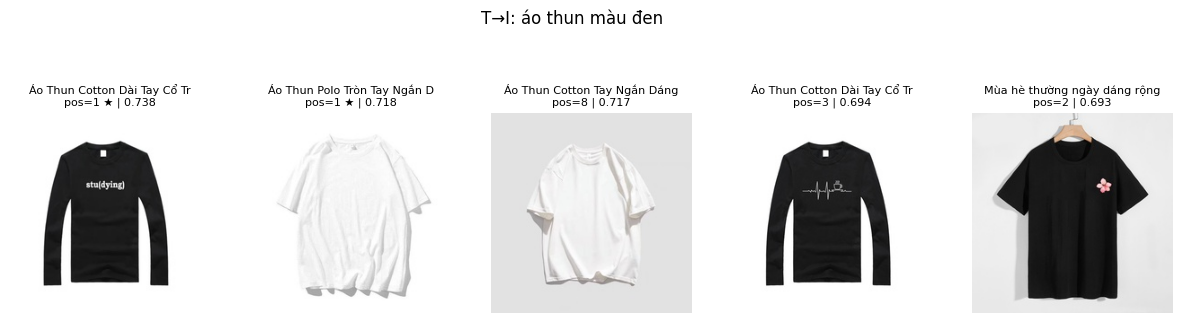

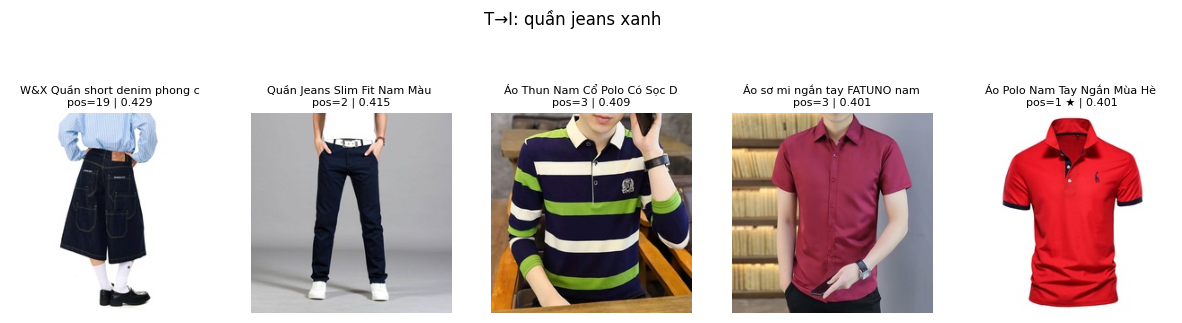

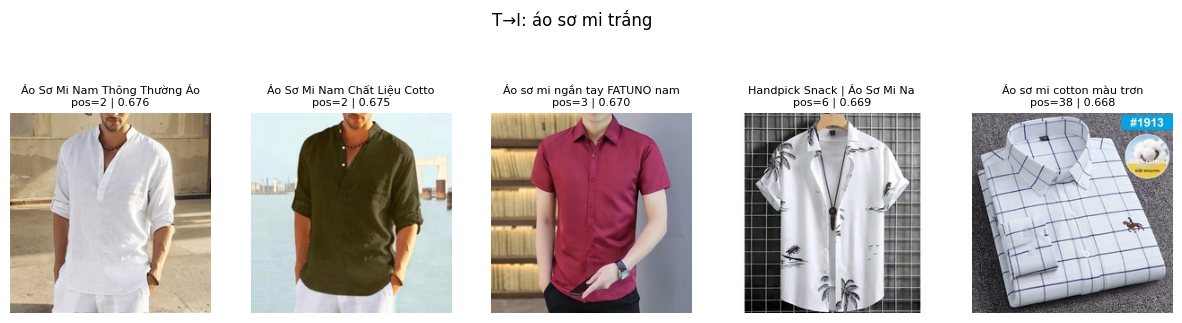

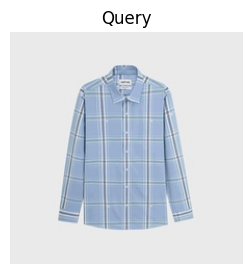

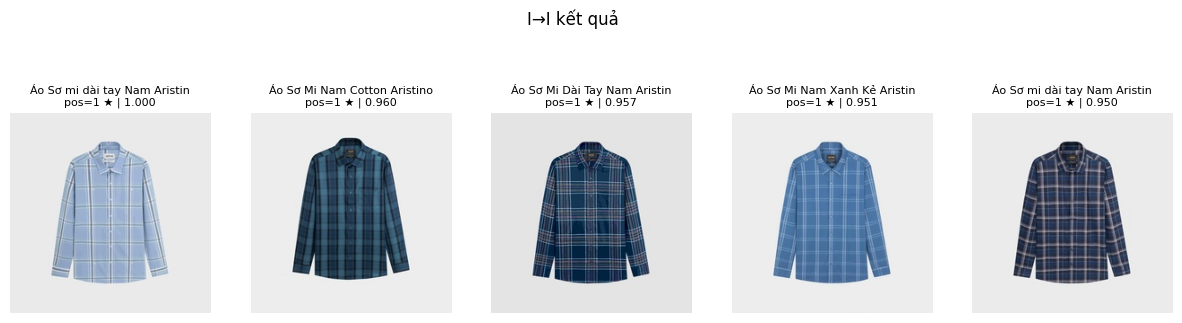

In [ ]:
def show(idxs, title, scores=None):
    fig, axs = plt.subplots(1, len(idxs), figsize=(3 * len(idxs), 4.2))
    if len(idxs) == 1: axs = [axs]
    for n, (ax, i) in enumerate(zip(axs, idxs)):
        ax.imshow(Image.open(f_paths[i])); ax.axis('off')
        t = f"{f_meta[i]['name'][:28]}\npos={f_pos[i]}{' ★' if f_primary[i] else ''}"
        if scores is not None: t += f' | {scores[n]:.3f}'
        ax.set_title(t, fontsize=8)
    fig.suptitle(title); plt.show()

def search_text(query, k=5):
    sims = (embed_texts([query]) @ full_gallery.T)[0]
    top = sims.topk(k)
    show(top.indices.tolist(), f'T→I: {query}', top.values.tolist())

def search_image(img_path, k=5):
    """Ảnh upload phải qua prepare_query_image (to_square) như API."""
    im = Image.open(img_path)
    x = img_tf(prepare_query_image(im)).unsqueeze(0).to(device)
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
        q = model.encode_image(x).float().cpu()
    top = (q @ full_gallery.T)[0].topk(k)
    plt.figure(figsize=(3, 4)); plt.imshow(im); plt.axis('off'); plt.title('Query'); plt.show()
    show(top.indices.tolist(), 'I→I kết quả', top.values.tolist())

search_text('áo thun màu đen')
search_text('quần jeans xanh')
search_text('áo sơ mi trắng')
# Ảnh có sẵn trong gallery (kết quả đầu tiên sẽ là chính nó):
search_image(g_paths[4])
# search_image('/content/2.webp')